<p class="lead">This course teaches cheminformatics — computing with molecules — to people who can program but have never studied chemistry. It therefore begins where a chemistry course would: with what a molecule <em>is</em>. This first unit builds exactly the chemical vocabulary the rest of the course needs and no more. By the end you will be able to read a chemical structure, name its parts, predict whether it carries a charge in the body, and compute its basic properties in code. Nothing in later units is assumed without having been built here.</p>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain what a molecule is and why it is the central object of drug, agrochemical and materials discovery.</li>
<li>Read the part of the periodic table that matters for organic molecules and state the usual valence of C, H, N, O, S, P and the halogens.</li>
<li>Describe covalent bonds, bond order and aromaticity, and recognise the main functional groups.</li>
<li>Explain acidity/basicity and pKa, and predict the charge of a molecule at the pH of blood (7.4).</li>
<li>Explain hydrogen bonding and the hydrophobic effect, and connect them to solubility and lipophilicity (logP).</li>
<li>Use RDKit to turn a structure into a software object and compute its formula, weight and basic properties.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Run each code cell as you reach it and read the output before moving on. Green <strong>chemistry boxes</strong> define each chemical idea in plain language, usually with an analogy a programmer already has. The only library you must install in Google Colab is RDKit (<code>!pip install rdkit</code>); the rest — NumPy, pandas, matplotlib — are already there. RDKit is the open-source cheminformatics toolkit we use throughout; it is to molecules what pandas is to tables.</p></div>

In [1]:
# Setup. In Google Colab, run once:  !pip install rdkit
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rdkit
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, AllChem, Crippen, Lipinski, rdMolDescriptors
from rdkit.Chem.Draw import rdMolDraw2D
rdkit.RDLogger.DisableLog("rdApp.*")            # silence RDKit's valence warnings in this teaching notebook
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
print("RDKit", rdkit.__version__, "| a molecule is about to become a Python object")

RDKit 2026.03.4 | a molecule is about to become a Python object


## 1. Why molecules, and why compute with them

A **molecule** is a fixed group of atoms held together by chemical bonds; it is the smallest unit of a substance that keeps that substance's chemical identity. Water is three atoms (two hydrogen, one oxygen); the caffeine in your coffee is 24 atoms; a typical oral drug is 20–50 atoms; a protein is tens of thousands. Almost everything this course does treats a molecule as data: a thing you can store, search, compare, score and generate.

Molecules matter because their structure determines their behaviour. A painkiller works because its shape and chemistry let it bind one protein and not others; a pesticide, a dye, a battery electrolyte and a polymer are all molecules chosen or designed for a property. **Cheminformatics** (equivalently chemoinformatics) is the discipline that represents molecules in a computer and builds methods to predict and design those properties<sup class="c"><a href="#r10">[10]</a></sup> — the molecular counterpart of bioinformatics, which you may know from the companion course. The payoff is large: bringing one drug to market costs on the order of a billion dollars and more than a decade,<sup class="c"><a href="#r1">[1]</a></sup> and most of that spend is on molecules that fail. Any method that fails the bad molecules earlier, in a computer, is worth a great deal.

Let us make the central object concrete immediately. The cell below takes four everyday molecules written as text in the SMILES notation<sup class="c"><a href="#r2">[2]</a></sup> (Unit 3's subject; for now read it as "a molecule as a string") and turns each into an RDKit<sup class="c"><a href="#r3">[3]</a></sup> molecule object, then draws them.

water                formula H2O           1 heavy atoms, MW   18.0
ethanol (alcohol)    formula C2H6O         3 heavy atoms, MW   46.1
caffeine             formula C8H10N4O2    14 heavy atoms, MW  194.2
aspirin              formula C9H8O4       13 heavy atoms, MW  180.2


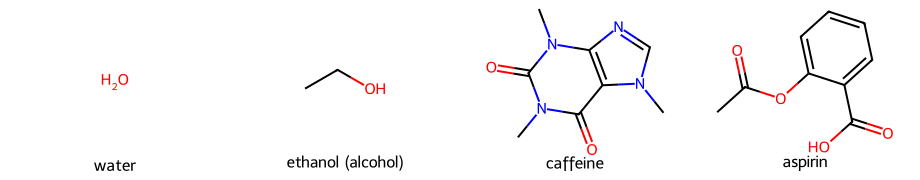

In [2]:
# Four everyday molecules: name -> SMILES string -> RDKit molecule object -> picture.
examples = {
    "water":        "O",
    "ethanol (alcohol)": "CCO",
    "caffeine":     "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
    "aspirin":      "CC(=O)Oc1ccccc1C(=O)O",
}
mols = [Chem.MolFromSmiles(s) for s in examples.values()]
for name, m in zip(examples, mols):
    print(f"{name:20s} formula {rdMolDescriptors.CalcMolFormula(m):12s} "
          f"{m.GetNumAtoms():2d} heavy atoms, MW {Descriptors.MolWt(m):6.1f}")
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(230, 180), legends=list(examples))

<p class="caption"><b>Figure 1.</b> Four molecules as RDKit draws them. Each line in the table was computed from the structure: the molecular formula, the number of "heavy" (non-hydrogen) atoms, and the molecular weight in g/mol. Notice the drawing convention that the next sections unpack — line ends and vertices are carbon atoms, hydrogens on carbon are not drawn, and the hexagon with a circle (or alternating double bonds) is a benzene ring. "Heavy atoms" is universal cheminformatics jargon for non-hydrogen atoms, because hydrogens are usually implicit.</p>

<div class="box bridge"><h4>Chemistry box — a molecule is a labelled graph</h4>
<p>The single most useful translation for a computer scientist: <strong>a molecule is a graph</strong>. Atoms are nodes, bonds are edges, and both carry labels (an atom's element and charge; a bond's order). Everything RDKit does starts from this graph. Unit 2 makes the graph explicit; here just hold the picture: the drawings above are graph layouts, and the string we passed in is a serialisation of the graph.</p></div>

## 2. Atoms, electrons and the periodic table — the part that matters

An **atom** is the smallest unit of a chemical element: a dense nucleus of positively charged protons and neutral neutrons, surrounded by negatively charged **electrons**. The number of protons (the <em>atomic number</em>) defines the element — 1 for hydrogen, 6 for carbon, 8 for oxygen. For cheminformatics you need only a handful of elements and one idea about their electrons.

The idea is **valence**: the number of bonds an atom usually forms, set by how many electrons it needs to fill its outer shell. Carbon forms 4, nitrogen 3, oxygen 2, hydrogen and the halogens (F, Cl, Br, I) 1. This single rule explains most of organic chemistry's "grammar": a carbon with four single bonds is saturated; an oxygen appears in the middle of a chain (two bonds, an ether) or at the end (one double bond, a carbonyl; or one single bond plus a hydrogen, a hydroxyl). The table below lists the elements that make up almost every drug.

In [3]:
# The elements of organic life and medicine, with their usual valence and why they recur.
periodic = pd.DataFrame([
    ("H",  1, 1, "forms 1 bond; caps the ends of every structure"),
    ("C",  6, 4, "the scaffold element: 4 bonds build chains and rings"),
    ("N",  7, 3, "amines, amides, aromatic rings; often basic (picks up H+)"),
    ("O",  8, 2, "alcohols, carbonyls, acids; hydrogen-bond acceptor/donor"),
    ("F",  9, 1, "blocks metabolism; very common in modern drugs"),
    ("P", 15, 5, "phosphates: DNA/RNA backbone, ATP, some prodrugs"),
    ("S", 16, 2, "thiols, thioethers, sulfonamides"),
    ("Cl",17, 1, "lipophilicity and potency tuning"),
    ("Br",35, 1, "heavier halogen; synthesis handle"),
    ("I", 53, 1, "contrast agents, thyroid drugs"),
], columns=["element", "atomic_number", "usual_valence", "role in drug-like molecules"])
# Confirm 'usual valence' against RDKit's default-valence model for the neutral atom.
pt = Chem.GetPeriodicTable()
periodic["rdkit_default_valence"] = [pt.GetDefaultValence(e) for e in periodic.element]
periodic

,element,atomic_number,usual_valence,role in drug-like molecules,rdkit_default_valence
0,H,1,1,forms 1 bond; caps the ends of every structure,1
1,C,6,4,the scaffold element: 4 bonds build chains and...,4
2,N,7,3,"amines, amides, aromatic rings; often basic (p...",3
3,O,8,2,"alcohols, carbonyls, acids; hydrogen-bond acce...",2
4,F,9,1,blocks metabolism; very common in modern drugs,1
5,P,15,5,"phosphates: DNA/RNA backbone, ATP, some prodrugs",3
6,S,16,2,"thiols, thioethers, sulfonamides",2
7,Cl,17,1,lipophilicity and potency tuning,1
8,Br,35,1,heavier halogen; synthesis handle,1
9,I,53,1,"contrast agents, thyroid drugs",1


The last two columns agree for the main-group elements (RDKit reports P and S with their common lower valences; both show expanded valences in sulfonamides and phosphates, which is why real structures sometimes surprise a naïve valence check — a theme of Unit 4). The practical lesson: of the 118 elements, organic molecules are built from about ten, and their valences are a short lookup table. That is why a molecular graph is so constrained and so predictable.

<div class="box bridge"><h4>Chemistry box — the octet rule, in one sentence</h4>
<p>Atoms bond so as to surround themselves with eight outer electrons (two for hydrogen) — the <em>octet rule</em>. Valence is just "how many bonds it takes to get there": carbon has four outer electrons and needs four more, so it forms four bonds. You will never compute with the octet rule directly, but it is why the valence table above is fixed, and why RDKit can flag an impossible structure.</p></div>

## 3. Covalent bonds, bond order and aromaticity

A **covalent bond** is a shared pair of electrons holding two atoms together — the edges of our graph. Bonds have an **order**: a single bond shares one pair, a double bond two, a triple bond three. Higher order means shorter, stronger, more rigid — the quantum-mechanical account of the shared-electron bond is Pauling's.<sup class="c"><a href="#r8">[8]</a></sup> In a drawing, a single line is a single bond, two lines a double bond, three a triple bond.

One pattern deserves its own name because it dominates drug molecules: **aromaticity**. A benzene ring is six carbons in a hexagon whose electrons are shared ("delocalised") evenly around the ring rather than fixed as alternating single and double bonds. Aromatic rings are flat, stable and extremely common. Chemists draw benzene either as a hexagon with three double bonds (a *Kekulé* structure) or as a hexagon with an inscribed circle (the aromatic form); they mean the same molecule. RDKit stores both views and converts between them — the conversion is called *kekulisation*, and it will matter in Unit 3.

benzene bond types (aromatic view): ['AROMATIC', 'AROMATIC', 'AROMATIC', 'AROMATIC', 'AROMATIC', 'AROMATIC']


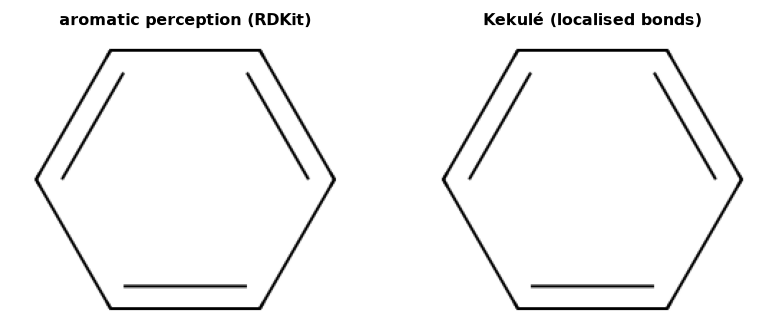

In [4]:
# The same benzene ring, drawn Kekulé (alternating double bonds) and aromatic (delocalised).
benz = Chem.MolFromSmiles("c1ccccc1")                 # lowercase = aromatic perception
kek = Chem.MolFromSmiles("C1=CC=CC=C1"); Chem.Kekulize(kek, clearAromaticFlags=True)
imgs = [Draw.MolToImage(benz, size=(240, 200)), Draw.MolToImage(kek, size=(240, 200))]
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.6))
for ax, im, t in zip(axes, imgs, ["aromatic perception (RDKit)", "Kekulé (localised bonds)"]):
    ax.imshow(np.array(im)); ax.axis("off"); ax.set_title(t, fontsize=9)
# Bond orders as RDKit sees the aromatic form:
orders = [str(b.GetBondType()) for b in benz.GetBonds()]
print("benzene bond types (aromatic view):", orders)
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> One molecule, two conventions. RDKit perceives the ring as aromatic (left; all six bonds are of type <code>AROMATIC</code>, as the printout shows) but can also express it with localised alternating double bonds (right). A cheminformatics system must treat these as the same molecule — the reason canonicalisation (Unit 3) and standardisation (Unit 4) exist.</p>

## 4. Functional groups — the vocabulary of organic chemistry

Most of a drug molecule is an inert carbon scaffold; its chemistry lives in small, recurring arrangements of atoms called **functional groups**. A functional group behaves roughly the same wherever it appears, so chemists — and cheminformatics systems, which can even enumerate them automatically<sup class="c"><a href="#r12">[12]</a></sup> — reason in terms of them: a carboxylic acid is acidic whether it sits on aspirin or on a fatty acid; an amine is basic wherever it appears. Learning the dozen common groups is like learning the keywords of a language. The cell below draws the essential set and detects each with a **SMARTS** pattern — a query language for substructures that is Unit 10's subject; here read each pattern as "a rule that matches this group".

  functional group        example   SMILES  SMARTS matches?
hydroxyl (alcohol)        ethanol      CCO             True
   carboxylic acid    acetic acid  CC(=O)O             True
   amine (primary)     ethylamine      CCN             True
             amide      acetamide  CC(=O)N             True
             ester methyl acetate CC(=O)OC             True
            ketone        acetone  CC(=O)C             True
             ether  diethyl ether    CCOCC             True
     aromatic ring        benzene c1ccccc1             True


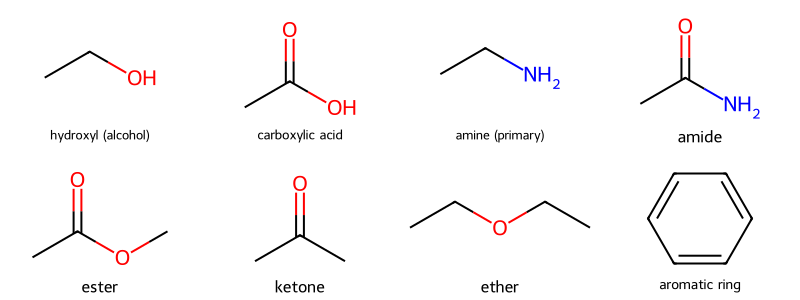

In [5]:
# The essential functional groups, each defined by a SMARTS substructure query.
groups = [
    ("hydroxyl (alcohol)", "ethanol",        "CCO",            "[CX4][OX2H]"),
    ("carboxylic acid",    "acetic acid",     "CC(=O)O",        "[CX3](=O)[OX2H1]"),
    ("amine (primary)",    "ethylamine",      "CCN",            "[NX3;H2][CX4]"),
    ("amide",              "acetamide",       "CC(=O)N",        "[CX3](=O)[NX3]"),
    ("ester",              "methyl acetate",  "CC(=O)OC",       "[CX3](=O)[OX2][CX4]"),
    ("ketone",             "acetone",         "CC(=O)C",        "[CX3](=O)[CX4]"),
    ("ether",              "diethyl ether",   "CCOCC",          "[OD2]([CX4])[CX4]"),
    ("aromatic ring",      "benzene",         "c1ccccc1",       "c1ccccc1"),
]
rows = []
mols = []
for gname, cname, smi, smarts in groups:
    m = Chem.MolFromSmiles(smi); q = Chem.MolFromSmarts(smarts)
    rows.append((gname, cname, smi, bool(m.GetSubstructMatch(q))))
    mols.append(m)
print(pd.DataFrame(rows, columns=["functional group", "example", "SMILES", "SMARTS matches?"]).to_string(index=False))
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(200, 150), legends=[g[0] for g in groups])

<p class="caption"><b>Figure 3.</b> Eight functional groups and a molecule that contains each. Every SMARTS query matched its intended group (last column all <code>True</code>) — a preview of the substructure searching that powers library filtering (Unit 10) and structural alerts (Unit 9). The red/blue colouring RDKit uses marks oxygen (red) and nitrogen (blue); carbon and hydrogen are left uncoloured. Committing these eight groups, plus a handful more (nitro, sulfonamide, halide, nitrile), to memory will make every later unit easier to read.</p>

## 5. Acids, bases and charge at the pH of the body

Whether a molecule carries an electrical **charge** is one of the most consequential things about it: charge controls solubility, whether a molecule can cross a cell membrane, and how it binds a target. Charge is set by **acid–base chemistry**.

An **acid** is a molecule that tends to give up a hydrogen ion (a proton, H⁺); a **base** tends to accept one. How strongly is measured by the **pKa**: the pH at which half the molecules have given up (or accepted) the proton. The rule you need is simple and quantitative — the Henderson–Hasselbalch relationship:

<div class="eq">$$\frac{[\text{deprotonated}]}{[\text{protonated}]} = 10^{\,\text{pH} - \text{p}K_a}$$
<span class="where">At a pH well above an acid's pKa it is mostly deprotonated (and negatively charged); well below, mostly neutral. For a base it is the mirror image. Blood is held at <strong>pH 7.4</strong>, so that is the pH at which a drug's charge is usually judged.</span></div>

A carboxylic acid (pKa ≈ 4) sits about 3.4 units below pH 7.4, so by the formula it is ~2500:1 deprotonated — essentially fully negative (−1) in the body. An aliphatic amine (pKa of its conjugate acid ≈ 10) is ~400:1 protonated — essentially fully positive (+1). The cell below shows both the neutral forms you draw and the charged forms that actually exist at pH 7.4.

acid deprotonated at pH 7.4: 100.0%   base protonated at pH 7.4: 99.7%


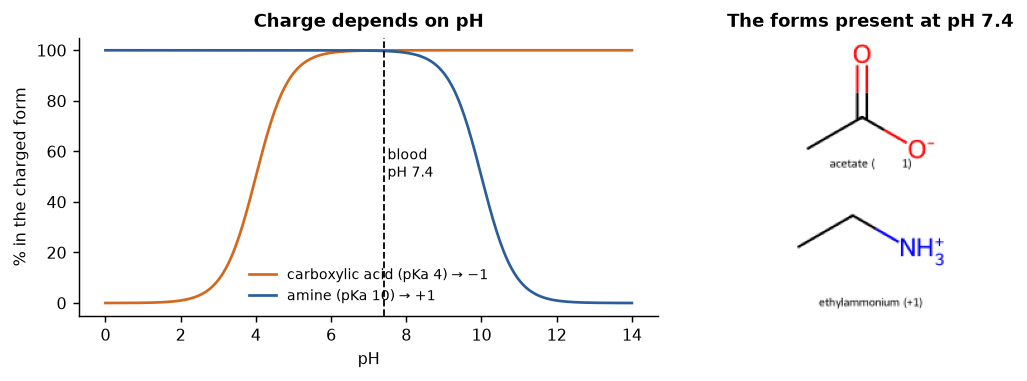

In [6]:
# Henderson-Hasselbalch: fraction ionised vs pH, and the dominant form at blood pH for an acid and a base.
pH = np.linspace(0, 14, 281)
def frac_ionised_acid(pH, pKa):  # fraction deprotonated (charged -1)
    return 1 / (1 + 10 ** (pKa - pH))
def frac_ionised_base(pH, pKa):  # fraction protonated (charged +1); pKa of the conjugate acid
    return 1 / (1 + 10 ** (pH - pKa))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8.6, 3.0), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.plot(pH, 100*frac_ionised_acid(pH, 4.0), color="#d2691e", label="carboxylic acid (pKa 4) → −1")
ax1.plot(pH, 100*frac_ionised_base(pH, 10.0), color="#2b5d9b", label="amine (pKa 10) → +1")
ax1.axvline(7.4, color="k", ls="--", lw=1); ax1.text(7.5, 50, "blood\npH 7.4", fontsize=8)
ax1.set_xlabel("pH"); ax1.set_ylabel("% in the charged form"); ax1.legend(fontsize=7.5, frameon=False)
ax1.set_title("Charge depends on pH")
# the acetic-acid anion and the ethylammonium cation as they exist at pH 7.4
charged = [Chem.MolFromSmiles("CC(=O)[O-]"), Chem.MolFromSmiles("CC[NH3+]")]
ax2.imshow(np.array(Draw.MolsToGridImage(charged, molsPerRow=1, subImgSize=(210, 110),
           legends=["acetate (−1)", "ethylammonium (+1)"]))); ax2.axis("off")
ax2.set_title("The forms present at pH 7.4")
print("acid deprotonated at pH 7.4: %.1f%%   base protonated at pH 7.4: %.1f%%"
      % (100*frac_ionised_acid(7.4, 4.0), 100*frac_ionised_base(7.4, 10.0)))
fig.tight_layout()

<p class="caption"><b>Figure 4.</b> Left: the fraction of molecules in the charged form as pH changes; at blood pH (dashed line) the acid is 99.96 % negatively charged and the amine 99.75 % positively charged, as the printout confirms. Right: the species that therefore actually exist in the body — an <em>anion</em> and a <em>cation</em>, not the neutral forms one usually draws. This matters enormously downstream: the charged form is what binds a protein and what a descriptor should describe, which is why Unit 4 spends a whole lesson on assigning the right protonation state before any modelling.</p>

<div class="box warn"><h4>A common trap</h4><p>The SMILES you copy from a database is usually the neutral drawing. If you compute properties or fingerprints on the neutral form when the molecule is charged at physiological pH, every downstream number is subtly wrong. "Standardise, then protonate, then model" is the mantra of Unit 4.</p></div>

## 6. Why molecules stick: intermolecular forces, water and lipophilicity

Covalent bonds hold a molecule together. Weaker forces <em>between</em> molecules decide whether a substance dissolves in water, crosses a membrane or binds a protein. Three matter for us.

- **Hydrogen bonds.** When hydrogen is attached to a strongly electron-hungry atom (N, O, F) it carries a small positive charge and is attracted to a lone pair on another N/O/F. A hydrogen bond is about a tenth the strength of a covalent bond but there are many of them, and they are directional. The atom bearing the H is a **donor**; the atom offering the lone pair is an **acceptor**. Water is the archetype: every water molecule donates and accepts hydrogen bonds, which is why it is liquid at room temperature.
- **The hydrophobic effect.** Oily (non-polar) parts of a molecule cannot hydrogen-bond to water, so water is forced to order itself around them, which is entropically costly. The system responds by hiding oily surfaces together, away from water. This "hydrophobic effect" is the main driving force of a drug binding into a protein pocket and of a membrane forming; the same polarity idea underlies hydropathy analysis of proteins.<sup class="c"><a href="#r9">[9]</a></sup>
- **Van der Waals forces.** Weak, universal attractions between any atoms in close contact; individually tiny, collectively important for shape-complementary binding.

The balance between a molecule's affinity for water and for oil is summarised by one number every cheminformatician quotes: **logP**, the (base-10) logarithm of how a compound partitions between octanol (an oil surrogate) and water. logP > 0 means "prefers oil" (lipophilic); logP < 0 means "prefers water" (hydrophilic). It is closely tied to solubility, membrane permeability and promiscuous binding. A related modern concern is that overly flat, aromatic-heavy molecules often fare worse as drugs than more three-dimensional ones.<sup class="c"><a href="#r11">[11]</a></sup> RDKit estimates logP from structure with the Crippen method,<sup class="c"><a href="#r6">[6]</a></sup> and estimates the hydrogen-bonding and polar-surface descriptors<sup class="c"><a href="#r7">[7]</a></sup> that recur through the whole course.

In [7]:
# Count hydrogen-bond donors/acceptors and estimate lipophilicity for a spread of real molecules.
mols_props = {
    "water": "O", "ethanol": "CCO", "glucose": "OCC1OC(O)C(O)C(O)C1O",
    "benzene": "c1ccccc1", "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "caffeine": "Cn1cnc2c1c(=O)n(C)c(=O)n2C", "ibuprofen": "CC(C)Cc1ccc(C(C)C(=O)O)cc1",
    "atorvastatin": "CC(C)c1c(C(=O)Nc2ccccc2)c(-c2ccccc2)c(-c2ccc(F)cc2)n1CCC(O)CC(O)CC(=O)O",
}
rows = []
for name, smi in mols_props.items():
    m = Chem.MolFromSmiles(smi)
    rows.append((name, round(Descriptors.MolWt(m), 1), round(Crippen.MolLogP(m), 2),
                 Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m), round(Descriptors.TPSA(m), 1)))
props = pd.DataFrame(rows, columns=["name", "MW", "logP", "HBD", "HBA", "TPSA"]).set_index("name")
props

,MW,logP,HBD,HBA,TPSA
name,,,,,
water,18.0,-0.82,0,0,31.5
ethanol,46.1,-0.00,1,1,20.2
glucose,180.2,-3.22,5,6,110.4
benzene,78.1,1.69,0,0,0.0
aspirin,180.2,1.31,1,3,63.6
caffeine,194.2,-1.03,0,3,61.8
ibuprofen,206.3,3.07,1,1,37.3
atorvastatin,558.7,6.31,4,4,111.8


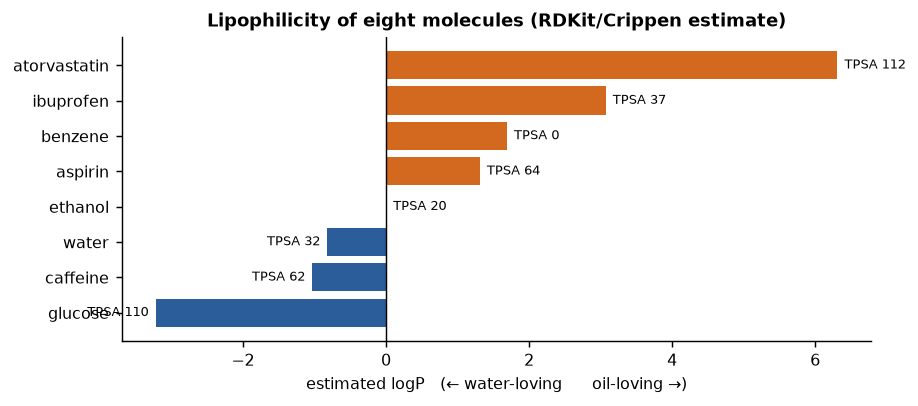

In [8]:
# logP orders the molecules from water-loving to oil-loving; TPSA (polar surface) tracks the opposite.
fig, ax = plt.subplots(figsize=(7.2, 3.2))
order = props.sort_values("logP")
colors = ["#2b5d9b" if v < 0 else "#d2691e" for v in order["logP"]]
ax.barh(order.index, order["logP"], color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("estimated logP   (← water-loving      oil-loving →)")
ax.set_title("Lipophilicity of eight molecules (RDKit/Crippen estimate)")
for y, (lp, tpsa) in enumerate(zip(order["logP"], order["TPSA"])):
    ax.text(lp + (0.1 if lp >= 0 else -0.1), y, f"TPSA {tpsa:.0f}", va="center",
            ha="left" if lp >= 0 else "right", fontsize=7)
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> The eight molecules ranked by estimated logP. Sugar and water sit far on the water-loving side (negative logP, high polar surface area); benzene and the lipophilic drug atorvastatin sit on the oil-loving side. The annotation shows the topological polar surface area (TPSA), the summed area of polar (N/O) atoms, which moves opposite to logP — polar molecules love water. These five numbers (MW, logP, hydrogen-bond donors and acceptors, TPSA) are exactly the ones Lipinski's "rule of five" uses to flag poorly absorbed drugs,<sup class="c"><a href="#r4">[4]</a></sup> the subject of Unit 9, and that are combined into a single "drug-likeness" score (QED) we meet there<sup class="c"><a href="#r5">[5]</a></sup>; you have now met them at their source.</p>

<div class="box bridge"><h4>Chemistry box — "like dissolves like", quantified</h4>
<p>Polar molecules (many N/O, high TPSA, low logP) dissolve in polar water; non-polar molecules (few heteroatoms, high logP) dissolve in oils and fats. A drug has to be soluble enough to travel in the blood yet lipophilic enough to cross the fatty cell membrane — a tension that logP captures in a single number and that explains much of why most molecules fail as drugs.</p></div>

## 7. A molecule as a software object

Everything above is already computable because RDKit represents the molecular graph as an object you can iterate over. This is the mental model to carry into every later unit: a molecule is an object with atoms and bonds you can loop through, each exposing its element, charge, degree and aromaticity. The cell makes the graph explicit by walking caffeine atom by atom and bond by bond.

In [9]:
# Walk the molecular graph of caffeine: atoms (nodes) and bonds (edges) with their labels.
caf = Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C")
atom_rows = [(a.GetIdx(), a.GetSymbol(), a.GetDegree(), a.GetTotalNumHs(),
              a.GetFormalCharge(), a.GetIsAromatic()) for a in caf.GetAtoms()]
atoms = pd.DataFrame(atom_rows, columns=["idx", "element", "degree", "implicit_H", "charge", "aromatic"])
print("caffeine has", caf.GetNumAtoms(), "heavy atoms and", caf.GetNumBonds(), "bonds")
print("element counts:", atoms.element.value_counts().to_dict())
print("aromatic atoms:", int(atoms.aromatic.sum()), "| first six atoms:")
atoms.head(6)

caffeine has 14 heavy atoms and 15 bonds
element counts: {'C': 8, 'N': 4, 'O': 2}
aromatic atoms: 9 | first six atoms:


,idx,element,degree,implicit_H,charge,aromatic
0,0,C,1,3,0,False
1,1,N,3,0,0,True
2,2,C,2,1,0,True
3,3,N,2,0,0,True
4,4,C,3,0,0,True
5,5,C,3,0,0,True


A is symmetric: True | each row sums to that atom's heavy-atom degree
degrees from the matrix: [1, 3, 2, 2, 3, 3, 3, 1, 3, 1, 3, 1, 3, 1]


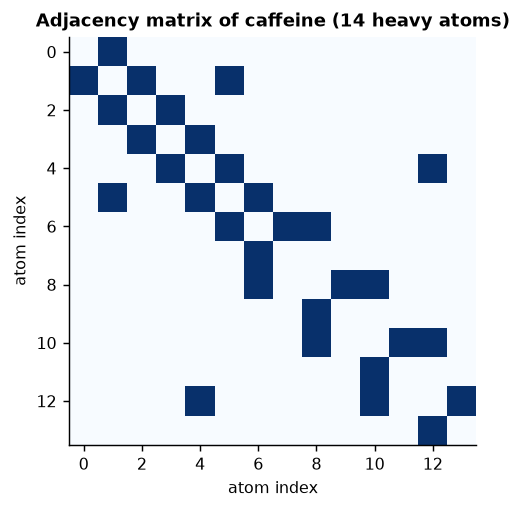

In [10]:
# The adjacency matrix: the molecular graph as the object a computer scientist already knows.
A = Chem.GetAdjacencyMatrix(caf)
fig, ax = plt.subplots(figsize=(4.4, 4.0))
ax.imshow(A, cmap="Blues"); ax.set_title("Adjacency matrix of caffeine (14 heavy atoms)")
ax.set_xlabel("atom index"); ax.set_ylabel("atom index")
print("A is symmetric:", bool((A == A.T).all()), "| each row sums to that atom's heavy-atom degree")
print("degrees from the matrix:", A.sum(1).tolist())
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Caffeine as an adjacency matrix — the same object a computer scientist uses for any graph. It is symmetric (an undirected graph), and each row sums to the atom's heavy-atom degree. Unit 2 builds on exactly this: atom and bond <em>features</em> attached to the nodes and edges turn the molecular graph into the input of the graph-neural-network methods of Unit 15. The whole course is, in a sense, feature engineering and learning on this graph.</p>

## 8. Worked example by hand: the degree of unsaturation

A quick paper-and-pencil check chemists use is the **degree of unsaturation** (also called rings-plus-double-bonds, or the double-bond equivalent, DBE): how many rings and multiple bonds a molecule has, computed from its formula alone. For a formula C\(_c\)H\(_h\)N\(_n\)O\(_o\) (halogens X count like H; oxygen does not enter), the formula is

<div class="eq">$$\text{DBE} = \frac{2c + 2 + n - h - x}{2}$$
<span class="where">Each ring and each double bond contributes 1; a triple bond contributes 2. The number must be a non-negative integer for a valid neutral formula — a cheap sanity check.</span></div>

Take **aspirin**, C₉H₈O₄ (we will read c, h, o from the structure). By hand: $\text{DBE} = (2\cdot 9 + 2 + 0 - 8 - 0)/2 = (18 + 2 - 8)/2 = 12/2 = 6$. Aspirin should therefore have 6 rings-plus-multiple-bonds: the benzene ring counts as 4 (one ring + three aromatic "double bonds"), the acid C=O is 1, and the ester C=O is 1 — total 6. The cell confirms the arithmetic and checks it against RDKit's own count of rings and π bonds.

In [11]:
# Degree of unsaturation from the formula, confirmed by counting rings + multiple bonds in the graph.
def dbe_from_formula(mol):
    from collections import Counter
    mol_h = Chem.AddHs(mol)
    c = Counter(a.GetSymbol() for a in mol_h.GetAtoms())
    C, H = c.get("C", 0), c.get("H", 0)
    N = c.get("N", 0)
    X = sum(c.get(x, 0) for x in ("F", "Cl", "Br", "I"))
    return (2*C + 2 + N - H - X) / 2

def dbe_from_graph(mol):
    rings = rdMolDescriptors.CalcNumRings(mol)                  # number of smallest-set rings
    extra_bond_order = sum(int(b.GetBondTypeAsDouble()) - 1 for b in mol.GetBonds())
    return rings + extra_bond_order

for name, smi in [("aspirin", "CC(=O)Oc1ccccc1C(=O)O"), ("caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C"),
                  ("benzene", "c1ccccc1"), ("ethanol", "CCO")]:
    m = Chem.MolFromSmiles(smi)
    mk = Chem.MolFromSmiles(smi); Chem.Kekulize(mk, clearAromaticFlags=True)   # count π bonds on localised form
    print(f"{name:9s} formula {rdMolDescriptors.CalcMolFormula(m):10s} "
          f"DBE(formula)={dbe_from_formula(m):.0f}  DBE(graph)={dbe_from_graph(mk):.0f}")

aspirin   formula C9H8O4     DBE(formula)=6  DBE(graph)=6
caffeine  formula C8H10N4O2  DBE(formula)=6  DBE(graph)=6
benzene   formula C6H6       DBE(formula)=4  DBE(graph)=4
ethanol   formula C2H6O      DBE(formula)=0  DBE(graph)=0


The two independent routes agree for every molecule (aspirin 6, caffeine 6, benzene 4, ethanol 0), which is the point of a sanity check: a formula and a structure that disagree signal a parsing or valence error — exactly the kind of bug Unit 4's standardisation catches at scale. You have now computed a classical chemistry quantity two ways in code, which is the rhythm of the whole course: a chemical idea, then the few lines that make it operational.

## 9. Summary

You should now be able to explain, without notes:

- What a molecule is, why its structure determines its properties, and why cheminformatics treats it as data.
- A molecule as a labelled graph (atoms = nodes, bonds = edges) and as an RDKit object you can iterate.
- The ten elements of organic chemistry and the valence rule that constrains the graph.
- Covalent bonds and bond order; aromaticity and the Kekulé/aromatic duality that forces canonicalisation.
- The common functional groups and that they can be detected by substructure queries.
- Acidity, basicity, pKa and the Henderson–Hasselbalch rule; how to predict a molecule's charge at pH 7.4 and why that charge matters.
- Hydrogen bonds, the hydrophobic effect and logP; the five properties (MW, logP, HBD, HBA, TPSA) that recur throughout the course.
- How to compute a molecular formula, weight, descriptors, the adjacency matrix and the degree of unsaturation in RDKit.

## 10. Self-assessment

<details><summary>1. Why is "a molecule is a labelled graph" the most useful sentence in this unit for a computer scientist?</summary>Because it maps chemistry onto a data structure you already know: atoms are nodes with labels (element, charge), bonds are edges with labels (order). Every representation (SMILES, fingerprints), search (substructure) and model (graph neural networks) in the course operates on this graph.</details>

<details><summary>2. Carbon, nitrogen and oxygen have valences 4, 3 and 2. How many hydrogens are implied on the carbon, nitrogen and oxygen of the molecule CN O written as "CNO" bonded in a chain?</summary>In a C–N–O chain: carbon uses 1 bond (to N) and fills the other 3 with H (CH₃); nitrogen uses 2 bonds (to C and O) and takes 1 H (NH); oxygen uses 1 bond (to N) and takes 1 H (OH). RDKit assigns implicit hydrogens by exactly this valence bookkeeping.</details>

<details><summary>3. A drawing shows a hexagon with an inscribed circle. What is it, and why might a program need to rewrite it with alternating double bonds?</summary>A benzene (aromatic) ring. Some file formats and algorithms require <em>kekulised</em> structures with localised single/double bonds, so RDKit must convert the aromatic perception to a valid alternating-bond pattern (kekulisation) — a step that can fail on malformed input, as Unit 3/4 discuss.</details>

<details><summary>4. A carboxylic acid has pKa ≈ 4. Using Henderson–Hasselbalch, what fraction is charged at pH 7.4, and what is the charge?</summary>ratio deprotonated:protonated = 10^(7.4−4) ≈ 2500:1, so ≈ 99.96 % is deprotonated, carrying charge −1. It exists in the body as the anion, not the neutral acid.</details>

<details><summary>5. Why can computing a fingerprint on the neutral drawing of an amine-containing drug give a misleading model?</summary>At pH 7.4 the amine is protonated (+1); the neutral and protonated forms have different hydrogen-bond donor counts and electronic features, so descriptors and fingerprints differ. A model trained on the wrong protonation state learns the wrong chemistry — hence standardise-then-protonate before modelling (Unit 4).</details>

<details><summary>6. logP is +3 for one molecule and −1 for another. Which is more water-soluble, and which more likely to cross a cell membrane?</summary>The logP = −1 molecule is more water-soluble (prefers water); the logP = +3 molecule is more lipophilic and more likely to cross the fatty membrane. Good oral drugs need a balance, which is why rules of thumb cap logP around 5.</details>

<details><summary>7. What does the hydrophobic effect contribute to a drug binding its target protein?</summary>Burying the drug's non-polar surface in the protein's pocket releases ordered water back to bulk solvent, an entropic gain that is often the main driving force of binding. It is why lipophilic groups frequently raise potency — and why they also raise the risk of promiscuous binding.</details>

<details><summary>8. The adjacency matrix of a molecule is symmetric and each row sums to a small integer. What is that integer, and why is it small?</summary>Each row sums to the atom's heavy-atom degree (number of non-hydrogen neighbours). It is small because valence caps it: carbon ≤ 4, oxygen ≤ 2, etc. Molecular graphs are sparse and low-degree, which is why cheminformatics algorithms are fast.</details>

<details><summary>9. Compute the degree of unsaturation of benzene (C₆H₆) by hand and say what it counts.</summary>DBE = (2·6 + 2 − 6)/2 = 8/2 = 4. It counts one ring plus the three aromatic double bonds of benzene.</details>

<details><summary>10. Which five properties introduced here are the ones Lipinski's rule of five uses, and what do they jointly describe?</summary>Molecular weight, logP, hydrogen-bond donors, hydrogen-bond acceptors (and relatedly TPSA). Jointly they describe passive oral absorption / "drug-likeness" — a molecule's ability to dissolve and cross membranes (Unit 9).</details>

<details><summary>11. A formula gives a degree of unsaturation of 3.5. What should a cheminformatics pipeline conclude?</summary>That something is wrong: DBE must be a non-negative integer for a valid neutral formula. A half-integer signals a wrong atom count, an unusual charge/radical, or a parsing error — a cheap validity check before any modelling.</details>

<details><summary>12. Why does the course insist on teaching chemistry and informatics together rather than one then the other?</summary>Because every informatics choice (which descriptor, which standardisation, which split) is a chemical judgement in disguise; a method applied without the chemistry it encodes produces confident, wrong results — the recurring warning of the course.</details>

## Glossary

<dl class="gloss">
<dt>Atom / element</dt><dd>The smallest unit of matter with a given number of protons (the atomic number, which names the element).</dd>
<dt>Aromaticity</dt><dd>Delocalisation of electrons around a flat ring (e.g. benzene) giving special stability; drawn as a circle or as alternating double bonds (Kekulé).</dd>
<dt>Bond order</dt><dd>The number of shared electron pairs in a covalent bond: single (1), double (2), triple (3).</dd>
<dt>Covalent bond</dt><dd>A shared pair of electrons linking two atoms; the edges of the molecular graph.</dd>
<dt>Degree of unsaturation (DBE)</dt><dd>Rings plus multiple bonds, computable from the molecular formula; a validity check.</dd>
<dt>Functional group</dt><dd>A small recurring arrangement of atoms with characteristic chemistry (hydroxyl, carboxylic acid, amine, amide, …).</dd>
<dt>Hydrogen bond</dt><dd>A directional attraction between an H on N/O/F (donor) and a lone pair on another N/O/F (acceptor).</dd>
<dt>Hydrophobic effect</dt><dd>The tendency of non-polar surfaces to associate away from water; the main driving force of binding.</dd>
<dt>logP</dt><dd>Log of the octanol/water partition coefficient; a measure of lipophilicity (oil- vs water-loving).</dd>
<dt>Molecular graph</dt><dd>The representation of a molecule as nodes (atoms) and edges (bonds), each carrying labels.</dd>
<dt>pKa</dt><dd>The pH at which an acidic or basic group is half ionised; with pH it fixes a molecule's charge.</dd>
<dt>SMARTS</dt><dd>A query language for molecular substructures (Unit 10); used here to detect functional groups.</dd>
<dt>SMILES</dt><dd>A text notation for a molecule (Unit 3); the string we parse into an RDKit molecule.</dd>
<dt>TPSA</dt><dd>Topological polar surface area; the summed surface of polar (N/O) atoms, tracking water affinity.</dd>
<dt>Valence</dt><dd>The number of bonds an atom usually forms (C 4, N 3, O 2, H and halogens 1).</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Wouters OJ, McKee M, Luyten J. Estimated research and development investment needed to bring a new medicine to market, 2009–2018. <em>JAMA</em>. 2020;323(9):844–853. <a href="https://doi.org/10.1001/jama.2020.1166">doi:10.1001/jama.2020.1166</a></li>
<li id="r2">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31–36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r3">Landrum G. RDKit: Open-source cheminformatics. <a href="https://doi.org/10.5281/zenodo.591637">doi:10.5281/zenodo.591637</a> (software; see also <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>)</li>
<li id="r4">Lipinski CA, Lombardo F, Dominy BW, Feeney PJ. Experimental and computational approaches to estimate solubility and permeability in drug discovery and development settings. <em>Adv Drug Deliv Rev</em>. 1997;23(1–3):3–25. <a href="https://doi.org/10.1016/S0169-409X(96)00423-1">doi:10.1016/S0169-409X(96)00423-1</a></li>
<li id="r5">Bickerton GR, Paolini GV, Besnard J, Muresan S, Hopkins AL. Quantifying the chemical beauty of drugs. <em>Nat Chem</em>. 2012;4:90–98. <a href="https://doi.org/10.1038/nchem.1243">doi:10.1038/nchem.1243</a></li>
<li id="r6">Wildman SA, Crippen GM. Prediction of physicochemical parameters by atomic contributions. <em>J Chem Inf Comput Sci</em>. 1999;39(5):868–873. <a href="https://doi.org/10.1021/ci990307l">doi:10.1021/ci990307l</a></li>
<li id="r7">Ertl P, Rohde B, Selzer P. Fast calculation of molecular polar surface area as a sum of fragment-based contributions and its application to the prediction of drug transport properties. <em>J Med Chem</em>. 2000;43(20):3714–3717. <a href="https://doi.org/10.1021/jm000942e">doi:10.1021/jm000942e</a></li>
<li id="r8">Pauling L. <em>The Nature of the Chemical Bond</em>. 3rd ed. Cornell University Press; 1960. <a href="https://doi.org/10.1021/ja01355a027">doi:10.1021/ja01355a027</a> (foundational paper; the book has no DOI)</li>
<li id="r9">Kyte J, Doolittle RF. A simple method for displaying the hydropathic character of a protein. <em>J Mol Biol</em>. 1982;157(1):105–132. <a href="https://doi.org/10.1016/0022-2836(82)90515-0">doi:10.1016/0022-2836(82)90515-0</a></li>
<li id="r10">Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Revised ed. Springer; 2007. <a href="https://doi.org/10.1007/978-1-4020-6291-9">doi:10.1007/978-1-4020-6291-9</a></li>
<li id="r11">Lovering F, Bikker J, Humblet C. Escape from flatland: increasing saturation as an approach to improving clinical success. <em>J Med Chem</em>. 2009;52(21):6752–6756. <a href="https://doi.org/10.1021/jm901241e">doi:10.1021/jm901241e</a></li>
<li id="r12">Ertl P. An algorithm to identify functional groups in organic molecules. <em>J Cheminform</em>. 2017;9:36. <a href="https://doi.org/10.1186/s13321-017-0225-z">doi:10.1186/s13321-017-0225-z</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Clayden J, Greeves N, Warren S. <em>Organic Chemistry</em>. 2nd ed. Oxford University Press; 2012. — Chapters 1–5 for everything in this unit, at a chemist's depth.</li>
<li>Leach AR, Gillet VJ. <em>An Introduction to Chemoinformatics</em>. Springer; 2007. — The standard textbook of the field.</li>
<li>Gasteiger J, Engel T (eds.). <em>Chemoinformatics: A Textbook</em>. Wiley-VCH; 2003. — Encyclopaedic reference.</li>
<li>Bajorath J (ed.). <em>Chemoinformatics for Drug Discovery</em>. Wiley; 2014. — Applications-oriented chapters.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>RDKit documentation and "Getting Started in Python" — <a href="https://www.rdkit.org/docs/">rdkit.org/docs</a>.</li>
<li>TeachOpenCADD talktorials (Volkamer Lab) — <a href="https://projects.volkamerlab.org/teachopencadd/">projects.volkamerlab.org/teachopencadd</a>.</li>
<li>Practical Cheminformatics (P. Walters) — <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
<li>IUPAC Gold Book (definitions of chemical terms) — <a href="https://goldbook.iupac.org/">goldbook.iupac.org</a>.</li>
</ul>